# EDA DE LA VARIABLE OBJETIVO: SURVIVAL MONTHS

Cuaderno autocontenido: carga los datos, elimina `Status`, divide en train y test y hace el EDA del target **solo con train**. El test no se usa en ningún análisis.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import shapiro, boxcox
from sklearn.preprocessing import PowerTransformer
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.dummy import DummyRegressor

# Para mostrar las conclusiones como texto formateado (si no hay IPython, se imprimen)
try:
    from IPython.display import Markdown, display
    def conclusion(texto):
        display(Markdown(texto))
except ImportError:
    def conclusion(texto):
        print(texto)

## 1) CARGAR LOS DATOS

In [2]:
# Se prueba primero tu ruta y después otras habituales
rutas_candidatas = [
    r"C:\Users\bgran\REPO_PRUEBA\0926_DS_Profe\0926_DS_Beatriz\3-Machine Learning\Proyecto Machine Learning\01 data\01 raw\Breast_Cancer.csv",
    "../01 data/01 raw/Breast_Cancer.csv",
    "01 data/01 raw/Breast_Cancer.csv",
    "Breast_Cancer.csv",
    "/mnt/user-data/uploads/Breast_Cancer.csv",
]
archivo = next((r for r in rutas_candidatas if os.path.exists(r)), None)
if archivo is None:
    raise FileNotFoundError("No encuentro Breast_Cancer.csv. Pon su ruta en la variable 'archivo' o añádela a 'rutas_candidatas'.")
print("Leyendo:", archivo)

df = pd.read_csv(archivo)
df.columns = df.columns.str.strip()   # por si algún nombre de columna trae espacios
df.head()

Leyendo: C:\Users\bgran\REPO_PRUEBA\0926_DS_Profe\0926_DS_Beatriz\3-Machine Learning\Proyecto Machine Learning\01 data\01 raw\Breast_Cancer.csv


,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive


In [3]:
df.info()
nulos = int(df.isna().sum().sum())
duplicadas = int(df.duplicated().sum())
print("Valores vacíos:", nulos)
print("Filas duplicadas:", duplicadas)

<class 'pandas.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Age                     4024 non-null   int64
 1   Race                    4024 non-null   str  
 2   Marital Status          4024 non-null   str  
 3   T Stage                 4024 non-null   str  
 4   N Stage                 4024 non-null   str  
 5   6th Stage               4024 non-null   str  
 6   differentiate           4024 non-null   str  
 7   Grade                   4024 non-null   str  
 8   A Stage                 4024 non-null   str  
 9   Tumor Size              4024 non-null   int64
 10  Estrogen Status         4024 non-null   str  
 11  Progesterone Status     4024 non-null   str  
 12  Regional Node Examined  4024 non-null   int64
 13  Reginol Node Positive   4024 non-null   int64
 14  Survival Months         4024 non-null   int64
 15  Status                  4024 non

In [4]:
conclusion(f'''**Conclusión.** El archivo tiene {df.shape[0]} pacientes y {df.shape[1]} columnas. Valores vacíos: {nulos}. Filas repetidas: {duplicadas}.''')

**Conclusión.** El archivo tiene 4024 pacientes y 16 columnas. Valores vacíos: 0. Filas repetidas: 1.

Como son datos de pacientes reales anonimizados, no podemos eliminar la fila repetida porque pueden pertenecer a pacientes diferentes.

## 2) EL PROBLEMA

Queremos predecir la supervivencia en meses de pacientes de cáncer de mama con carcinoma ductal infiltrante y lobulillar infiltrante, para lo cual tenemos un dataset de 4024 pacientes femeninas diagnosticadas entre 2006 y 2010. Por lo que tenemos un proyecto de Machine Learning de Regresión.

## 3) EL TARGET

Nuestro target será la columna `Survival Months`. Por consiguiente, para que no haya una fuga de información, procederé a eliminar la columna `Status`, que nos indica si la paciente está viva o no, **antes de dividir en train y test**.

In [5]:
target = df['Survival Months']
df = df.drop(columns=['Status'])
print(df.columns.tolist())

['Age', 'Race', 'Marital Status', 'T Stage', 'N Stage', '6th Stage', 'differentiate', 'Grade', 'A Stage', 'Tumor Size', 'Estrogen Status', 'Progesterone Status', 'Regional Node Examined', 'Reginol Node Positive', 'Survival Months']


**Conclusión.** Se elimina `Status` antes de dividir en train y test por dos motivos:

1. **No se conoce en el momento de predecir.** Se rellena al final del seguimiento, cuando ya se sabe lo que ha pasado. Para una paciente nueva no se podría aportar.
2. **Va pegada al resultado.** Indica si los meses son una supervivencia real (paciente fallecida) o solo el tiempo que se ha seguido a la paciente (paciente viva). Usarla sería dar al modelo parte de la respuesta y las métricas saldrían mejores de lo real.

Se elimina antes de dividir (y no después) para que ninguna información suya llegue a train ni a test.

## 4) DIVIDIR EN TRAIN Y TEST

In [6]:
X_train, X_test, y_train, y_test = train_test_split(df.drop('Survival Months', axis=1),
                                                    df['Survival Months'],
                                                    test_size=0.2,
                                                    random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (3219, 14) | Test: (805, 14)


In [ ]:
# Opcional: guardar los conjuntos en disco (déjalo en False hasta tener decidido el preprocesado)
GUARDAR = False

if GUARDAR:
    os.makedirs("../01 data/03 train", exist_ok=True)
    os.makedirs("../01 data/04 test", exist_ok=True)
    X_train.to_csv("../01 data/03 train/X_train.csv", index=False)
    y_train.to_frame().to_csv("../01 data/03 train/y_train.csv", index=False)
    X_test.to_csv("../01 data/04 test/X_test.csv", index=False)
    y_test.to_frame().to_csv("../01 data/04 test/y_test.csv", index=False)
    print("Archivos guardados.")

In [7]:
conclusion(f'''**Conclusión.** Quedan {len(X_train)} pacientes para entrenar y {len(X_test)} para test. El test no se toca hasta la evaluación final.''')

**Conclusión.** Quedan 3219 pacientes para entrenar y 805 para test. El test no se toca hasta la evaluación final.

## 5) EDA

### 5.1) EDA VARIABLE OBJETIVO

- Estadística descriptiva

In [8]:
y_train.describe()

count    3219.000000
mean       71.162162
std        22.869855
min         1.000000
25%        56.000000
50%        73.000000
75%        89.000000
max       107.000000
Name: Survival Months, dtype: float64

In [9]:
print("Media:", y_train.mean())
print("Mediana:", y_train.median())
print("Moda:", y_train.mode())
print("Varianza:", y_train.var())
print("Desviación típica:", y_train.std())
print("Coeficiente de variación:", y_train.std() / y_train.mean())
print("Asimetría:", y_train.skew())
print("Curtosis:", y_train.kurtosis())

Media: 71.16216216216216
Mediana: 73.0
Moda: 0    69
Name: Survival Months, dtype: int64
Varianza: 523.0302521290713
Desviación típica: 22.869854659115596
Coeficiente de variación: 0.3213766131360718
Asimetría: -0.5800899664045127
Curtosis: -0.0028909026993471088


In [10]:
percentiles = y_train.quantile(
    [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print(percentiles)

0.01      9.0
0.05     27.0
0.10     43.0
0.25     56.0
0.50     73.0
0.75     89.0
0.90    100.0
0.95    103.0
0.99    107.0
Name: Survival Months, dtype: float64


In [11]:
media, mediana = y_train.mean(), y_train.median()
q1, q3 = percentiles[0.25], percentiles[0.75]
p5, p95 = percentiles[0.05], percentiles[0.95]
maximo = y_train.max()
asimetria = y_train.skew()

conclusion(f'''**Conclusión.** La mitad de las pacientes tiene entre {q1:.0f} y {q3:.0f} meses de supervivencia, con una mediana de {mediana:.0f} (la media es {media:.0f}). Nueve de cada diez están entre {p5:.0f} y {p95:.0f} meses y el máximo es {maximo:.0f}. Hay un grupo pequeño con supervivencias muy cortas (el 5 % no llega a {p5:.0f} meses) que baja un poco la media por debajo de la mediana (asimetría de {asimetria:.2f}).''')

**Conclusión.** La mitad de las pacientes tiene entre 56 y 89 meses de supervivencia, con una mediana de 73 (la media es 71). Nueve de cada diez están entre 27 y 103 meses y el máximo es 107. Hay un grupo pequeño con supervivencias muy cortas (el 5 % no llega a 27 meses) que baja un poco la media por debajo de la mediana (asimetría de -0.58).

- Análisis visual: distribución y outliers

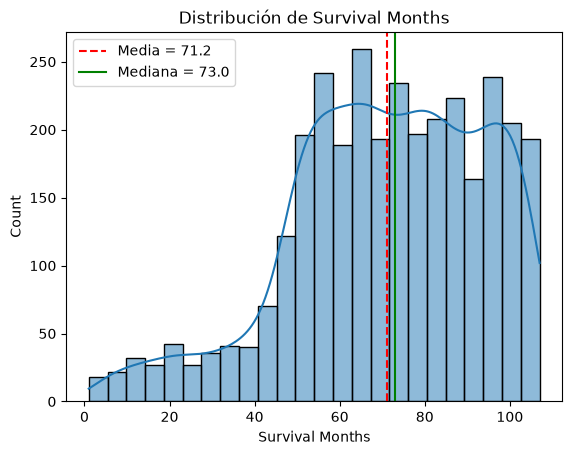

In [12]:
sns.histplot(y_train, kde=True)
plt.axvline(y_train.mean(), color="red", ls="--", label=f"Media = {y_train.mean():.1f}")
plt.axvline(y_train.median(), color="green", ls="-", label=f"Mediana = {y_train.median():.1f}")
plt.title("Distribución de Survival Months")
plt.legend()
plt.show()

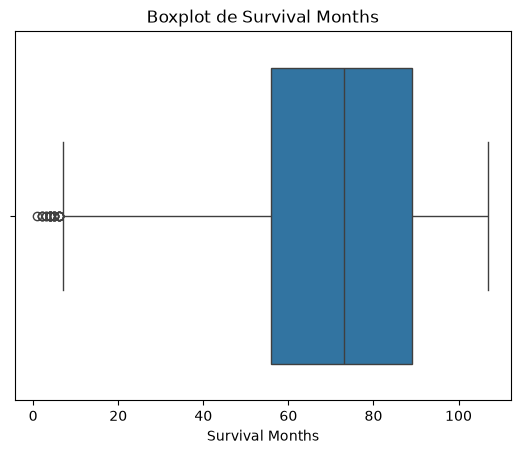

In [13]:
sns.boxplot(x=y_train)
plt.title('Boxplot de Survival Months')
plt.show()

In [14]:
menos47 = (y_train < 47).mean()

conclusion(f'''**Conclusión.** El histograma no tiene forma de campana: hay un grupo pequeño de pacientes con pocos meses (un {menos47:.0%} por debajo de 47) y, a partir de ahí, un bloque bastante parejo hasta los {maximo:.0f} meses. El boxplot solo marca como valores raros algunos muy bajos. Esta forma encaja con que el dato mezcla supervivencia real con tiempo de seguimiento: las pacientes se diagnosticaron entre 2006 y 2010 y se les siguió hasta una fecha de cierre, así que muchas vivas se quedan en ese bloque alto.''')

**Conclusión.** El histograma no tiene forma de campana: hay un grupo pequeño de pacientes con pocos meses (un 11% por debajo de 47) y, a partir de ahí, un bloque bastante parejo hasta los 107 meses. El boxplot solo marca como valores raros algunos muy bajos. Esta forma encaja con que el dato mezcla supervivencia real con tiempo de seguimiento: las pacientes se diagnosticaron entre 2006 y 2010 y se les siguió hasta una fecha de cierre, así que muchas vivas se quedan en ese bloque alto.

- Detección de outliers

In [15]:
# Detección de outliers en la variable objetivo usando solo y_train

Q1 = y_train.quantile(0.25)
Q3 = y_train.quantile(0.75)

IQR = Q3 - Q1

lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

outliers = y_train[
    (y_train < lim_inf) |
    (y_train > lim_sup)
]

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Límite inferior: {lim_inf:.2f}")
print(f"Límite superior: {lim_sup:.2f}")

print(f"\nNúmero de outliers: {len(outliers)}")
print(f"Porcentaje de outliers: {100 * len(outliers) / len(y_train):.2f}%")

Q1: 56.00
Q3: 89.00
IQR: 33.00
Límite inferior: 6.50
Límite superior: 138.50

Número de outliers: 24
Porcentaje de outliers: 0.75%


In [16]:
n_bajos = int((y_train < lim_inf).sum())
n_altos = int((y_train > lim_sup).sum())

conclusion(f'''**Conclusión.** Hay {len(outliers)} pacientes ({100 * len(outliers) / len(y_train):.1f} %) con valores raros: {n_bajos} por debajo de {lim_inf:.1f} meses y {n_altos} por encima de {lim_sup:.1f}. Son supervivencias muy cortas, algo que ocurre en la realidad y no parece un error de registro. Se mantienen.''')

**Conclusión.** Hay 24 pacientes (0.7 %) con valores raros: 24 por debajo de 6.5 meses y 0 por encima de 138.5. Son supervivencias muy cortas, algo que ocurre en la realidad y no parece un error de registro. Se mantienen.

- Evaluación de la normalidad

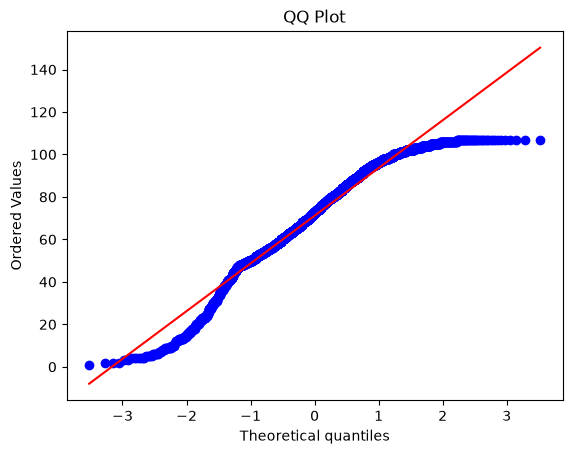

In [17]:
stats.probplot(
    y_train,
    dist="norm",
    plot=plt
)

plt.title("QQ Plot")
plt.show()

In [18]:
# Evaluación de normalidad: Test Shapiro-Wilk

sample = y_train.sample(
    min(5000, len(y_train)),
    random_state=42
)

stat, p = shapiro(sample)

print("Estadístico:", stat)
print("p-value:", p)

if p > 0.05:
    print("No se rechaza la hipótesis de normalidad")
else:
    print("Se rechaza la hipótesis de normalidad")

Estadístico: 0.9632651711820087
p-value: 7.283486018408745e-28
Se rechaza la hipótesis de normalidad


In [19]:
if p > 0.05:
    texto_norm = "No hay evidencia de que se aparte de una distribución normal"
else:
    texto_norm = "No sigue una distribución normal"

conclusion(f'''**Conclusión.** {texto_norm} (Shapiro p = {p:.1e}); en el QQ plot los puntos se separan de la recta, sobre todo en los extremos. Con tantas pacientes el test es muy exigente, así que lo que realmente importará es revisar los errores del modelo más adelante.''')

**Conclusión.** No sigue una distribución normal (Shapiro p = 7.3e-28); en el QQ plot los puntos se separan de la recta, sobre todo en los extremos. Con tantas pacientes el test es muy exigente, así que lo que realmente importará es revisar los errores del modelo más adelante.

- Transformaciones para conseguir una distribución normal en la variable objetivo

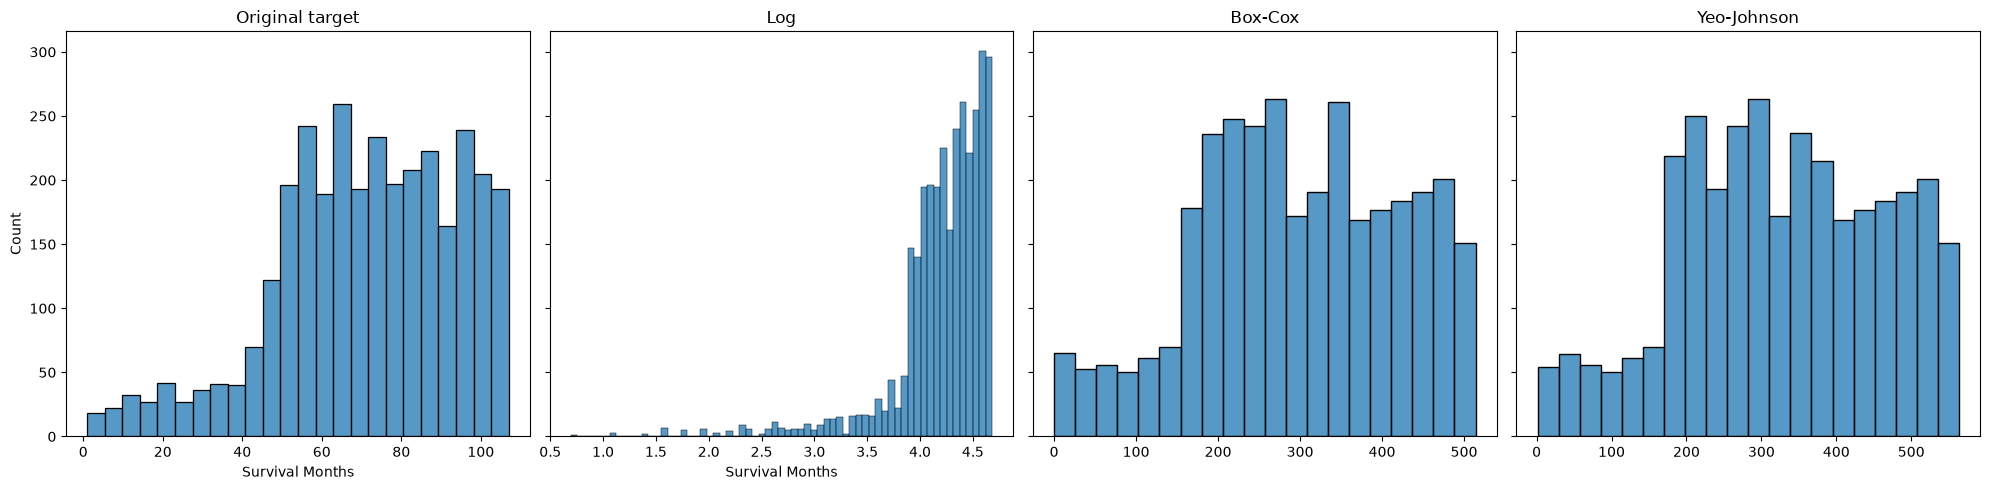

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

# Original target
sns.histplot(y_train, kde=False, ax=axes[0])
axes[0].set_title("Original target")

# Logaritmic
sns.histplot(np.log1p(y_train), kde=False, ax=axes[1])
axes[1].set_title("Log")

# Box-cox
sns.histplot(stats.boxcox(y_train)[0], kde=False, ax=axes[2])
axes[2].set_title("Box-Cox")

# Yeo-Johnson
pt = PowerTransformer(method='yeo-johnson', standardize=False)
y_yj = pt.fit_transform(y_train.to_numpy().reshape(-1, 1)).flatten()

sns.histplot(y_yj, kde=False, ax=axes[3])
axes[3].set_title("Yeo-Johnson")

plt.tight_layout()
plt.show()

In [21]:
y_train_log = np.log1p(y_train)

In [22]:
print("Variable original")
print("Asimetría:", y_train.skew())
print("Curtosis:", y_train.kurtosis())

print("\nTransformación log1p")
print("Asimetría:", y_train_log.skew())
print("Curtosis:", y_train_log.kurtosis())

Variable original
Asimetría: -0.5800899664045127
Curtosis: -0.0028909026993471088

Transformación log1p
Asimetría: -2.5792797437729593
Curtosis: 9.743237550556735


In [23]:
y_train_boxcox, lambda_bc = boxcox(y_train)

print("Lambda:", lambda_bc)
print("Asimetría:", pd.Series(y_train_boxcox).skew())
print("Curtosis:", pd.Series(y_train_boxcox).kurtosis())

print("Lambda Yeo-Johnson:", pt.lambdas_[0])
print("Asimetría:", stats.skew(y_yj))
print("Curtosis:", stats.kurtosis(y_yj))

Lambda: 1.4096015934258255
Asimetría: -0.20259781047886874
Curtosis: -0.6806283998857561
Lambda Yeo-Johnson: 1.4294634568638376
Asimetría: -0.1940894449548102
Curtosis: -0.6902139207850482


In [24]:
asim_orig = y_train.skew()
asim_log = y_train_log.skew()
asim_bc = pd.Series(y_train_boxcox).skew()
asim_yj = stats.skew(y_yj)

conclusion(f'''**Conclusión.** El logaritmo empeora la forma (la asimetría pasa de {asim_orig:.2f} a {asim_log:.2f}). Box-Cox y Yeo-Johnson la mejoran algo ({asim_bc:.2f} y {asim_yj:.2f}), pero la mejora es pequeña, casi idéntica entre ambas, y los meses dejarían de leerse tal cual. **Decisión: no transformar y trabajar con los meses originales.**''')

**Conclusión.** El logaritmo empeora la forma (la asimetría pasa de -0.58 a -2.58). Box-Cox y Yeo-Johnson la mejoran algo (-0.20 y -0.19), pero la mejora es pequeña, casi idéntica entre ambas, y los meses dejarían de leerse tal cual. **Decisión: no transformar y trabajar con los meses originales.**

### 5.2) PUNTO DE REFERENCIA (BASELINE)

Qué error se comete si se responde siempre lo mismo (la media o la mediana de train), calculado con validación cruzada dentro de train.

In [25]:
X_dummy = np.zeros((len(y_train), 1))
cv = KFold(n_splits=5, shuffle=True, random_state=42)

filas = {}
for estrategia in ["mean", "median"]:
    res = cross_validate(
        DummyRegressor(strategy=estrategia), X_dummy, y_train, cv=cv,
        scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"},
    )
    filas[estrategia] = {"MAE": -res["test_MAE"].mean(), "RMSE": -res["test_RMSE"].mean()}

baseline = pd.DataFrame(filas).T.round(2)
mae_dummy = baseline.loc["mean", "MAE"]
baseline

,MAE,RMSE
mean,18.59,22.87
median,18.56,22.93


In [26]:
conclusion(f'''**Conclusión.** Si el modelo respondiera siempre la media, se equivocaría de media en unos {mae_dummy:.1f} meses. Ese es el listón que tiene que superar cualquier modelo.''')

**Conclusión.** Si el modelo respondiera siempre la media, se equivocaría de media en unos 18.6 meses. Ese es el listón que tiene que superar cualquier modelo.

## 6) CONCLUSIONES FINALES

In [27]:
n_out = len(outliers)

conclusion(f'''
1. **`Status` se elimina antes de dividir.** No se conoce al predecir y va unida al propio resultado; usarla sería hacer trampa.
2. **El target.** La supervivencia mediana es de {mediana:.0f} meses y la mitad de las pacientes está entre {q1:.0f} y {q3:.0f}. No tiene forma de campana y mezcla supervivencia real con tiempo de seguimiento.
3. **Valores bajos y transformaciones.** Los {n_out} casos muy cortos parecen reales y se mantienen. Ninguna transformación compensa, así que se usan los meses originales.
4. **El listón.** Responder siempre la media da un error medio de {mae_dummy:.1f} meses. El modelo tiene que mejorarlo, aunque conviene no esperar una mejora enorme por la mezcla de la que habla el punto 2.
''')


1. **`Status` se elimina antes de dividir.** No se conoce al predecir y va unida al propio resultado; usarla sería hacer trampa.
2. **El target.** La supervivencia mediana es de 73 meses y la mitad de las pacientes está entre 56 y 89. No tiene forma de campana y mezcla supervivencia real con tiempo de seguimiento.
3. **Valores bajos y transformaciones.** Los 24 casos muy cortos parecen reales y se mantienen. Ninguna transformación compensa, así que se usan los meses originales.
4. **El listón.** Responder siempre la media da un error medio de 18.6 meses. El modelo tiene que mejorarlo, aunque conviene no esperar una mejora enorme por la mezcla de la que habla el punto 2.
